# Tiered checks and readaptation without labels

**Questions.** (1) The adaptive loop's uplink is almost all full frames fetched to check the code. How much of that can a 192-byte thumbnail check replace? (2) With a detector as teacher on every stream (no labels anywhere), how long does the loop take to readapt after the tag is moved, and how much of that is the bootstrap setting?

**Tiered checks** (`semwisp.server.TieredServer`). Each query asks for the 96-bit code. Then:
* on the check schedule (the same disagreement-driven interval as before), the server asks for a 16×12 thumbnail (192 B) and scores it with `ThumbDecoder`, a room decoder it learns online from the teacher's labels (running class statistics of |thumbnail − empty-room thumbnail|, a linear discriminant, an online calibration);
* a full frame (19,200 B) is fetched only if the thumbnail decoder is not ready, is unsure (below 0.9 either way), disagrees with the code, or after 4 trusted thumbnail checks in a row (so the teacher keeps supplying labels); also when the code reply has more than 40% of its bits set (the room no longer looks like the one the code was made for);
* an uncertain code answer (|logit| < 2) gets a thumbnail outside the schedule, which answers if it is confident and never escalates.

**Runs** (`experiments/tiered_checks.py`, results in `results/tiered_checks/`): streams `piropo` (two passes) and `switch` (PIROPO `training` → Mall tile → PIROPO rearranged), teachers `detector` and `oracle`, learners `online_pixels` (96 single pixels), `online_cells` (whole blocks) and `batch_cells` (store and refit, the baseline), checks `full` and `tiered`; and on `switch`, the bootstrap length swept from 25 to 400 labelled frames.

The detector teacher on the Mall tile is the same COCO detector on the 160×120 tile (`coco_detector_eval.py --mall-tile`): AUC 0.995 there, much better than its 0.86 balanced accuracy on PIROPO.

**Findings in brief** (first run, 2026-11-11; single runs, settings not tuned).
1. **Tiered checks cut the first-pass uplink by 1.4–1.7×, not by an order of magnitude.** On PIROPO with detector labels, 5.7 → 3.6 KB per query for the batch learner and 8.6 → 5.1 KB for the 96-pixel online learner, at roughly the same balanced accuracy (−0.03 to +0.01). With true labels the batch learner gains accuracy as well (0.904 → 0.922 at 3.3 KB).
2. **The full frames that remain are there for the teacher, not the code.** Full frames fall from 30–45% of queries to 17–26%. With detector labels, most of what is left are thumbnail checks the thumbnail decoder is unsure about: it learns from a teacher that is itself only 0.86 accurate on PIROPO, so it rarely becomes confident. Cheaper checks have moved the bottleneck to label quality.
3. **With no labels anywhere, the loop readapts after a move**: the online learner notices the new room within 14–48 queries and has a new code on the tag 230–255 queries after the move (with the 200-frame bootstrap). In the Mall tile its accuracy afterwards is 0.88–0.91; back in the rearranged PIROPO room it is 0.66–0.80.
4. **Readaptation time is detection (15–50 queries with detector labels) plus a setting.** A 25-frame bootstrap puts a new code on the tag 58 queries after the move to the Mall tile (446 with 400 frames). For the 96-pixel online learner the shorter bootstrap costs accuracy in the rearranged room (0.72 against 0.80 with detector labels); the batch baseline barely cares about bootstrap length (within 0.04).
5. **The batch baseline is still the better learner once a room is stable**, and with tiered checks it is the cheapest configuration. The online learner's advantage is its explicit change detection.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from semwisp.metrics import summary, readaptation, balanced_accuracy

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.edgecolor': '#b5b4ae', 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'lines.linewidth': 2})
from matplotlib.ticker import FuncFormatter, NullFormatter
def logx(ax):
    ax.set_xscale('log')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}')); ax.xaxis.set_minor_formatter(NullFormatter())
pd.set_option('display.precision', 3)
RES = Path('../results/tiered_checks')
runs = {}
for f in sorted(RES.glob('*.npz')):
    with np.load(f) as z:
        meta = json.loads(str(z['meta'])); n = len(z['label'])
        runs[f.stem] = (meta, pd.DataFrame({k: z[k] for k in z.files if k != 'meta' and z[k].shape == (n,)}))
print(len(runs), 'runs')
LC = dict(online_pixels=AQUA, online_cells=BLUE, batch_cells=ORANGE)

40 runs


## 0. How the loop works, in pictures

Before the numbers: what the tag and the server each do, what is sent each way, and which parts are learned. Everything after the two diagrams is real data from the runs analysed below.

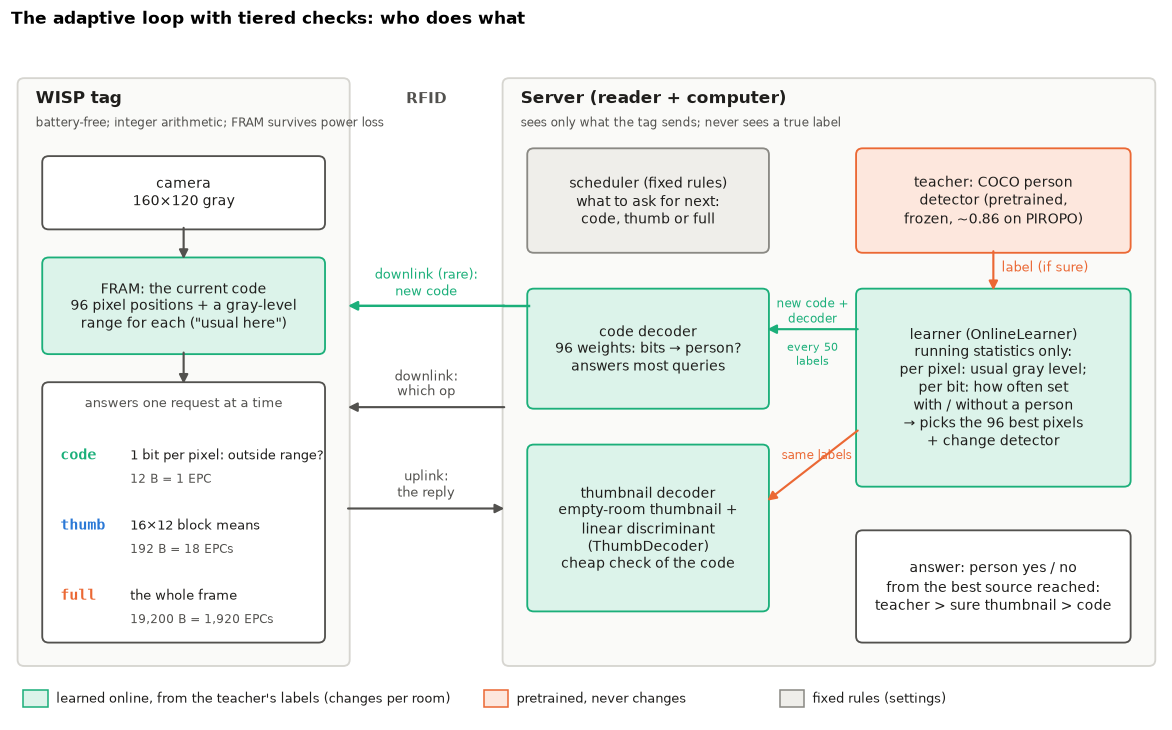

In [2]:
from matplotlib.patches import FancyBboxPatch, Polygon
INK, MUTED = '#1f1e1c', '#52514e'
TINT = dict(aqua='#dcf3ea', orange='#fde7dd', gray='#efeeea', blue='#e2ecfa', white='white')

def box(ax, x, y, w, h, text, fc='white', ec=MUTED, lw=1.2, fs=9, bold=False, ls='-'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.08', fc=fc, ec=ec, lw=lw, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, color=INK,
            fontweight='bold' if bold else 'normal', linespacing=1.3)

def diamond(ax, cx, cy, w, h, text, ec=MUTED, fs=8.5):
    ax.add_patch(Polygon([(cx - w / 2, cy), (cx, cy + h / 2), (cx + w / 2, cy), (cx, cy - h / 2)], closed=True,
                         fc='white', ec=ec, lw=1.2))
    ax.text(cx, cy, text, ha='center', va='center', fontsize=fs, color=INK, linespacing=1.2)

def arrow(ax, x0, y0, x1, y1, text=None, color=MUTED, fs=8.5, off=(0, 0.08), lw=1.4, ls='-', ha='center', rad=0):
    ax.annotate('', (x1, y1), (x0, y0), arrowprops=dict(arrowstyle='-|>', color=color, lw=lw, ls=ls, shrinkA=0,
                                                        shrinkB=0, mutation_scale=12, connectionstyle=f'arc3,rad={rad}'))
    if text:
        ax.text((x0 + x1) / 2 + off[0], (y0 + y1) / 2 + off[1], text, ha=ha, va='bottom', fontsize=fs, color=color,
                linespacing=1.25)

def canvas(w, h, figsize):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, w); ax.set_ylim(0, h); ax.axis('off')
    return fig, ax

def system_diagram():
    fig, ax = canvas(14, 8.4, (13.5, 8.1))
    # panels
    box(ax, 0.1, 0.3, 4.0, 7.5, '', fc='#fafaf8', ec='#d6d5d0')
    box(ax, 6.0, 0.3, 7.9, 7.5, '', fc='#fafaf8', ec='#d6d5d0')
    ax.text(0.3, 7.5, 'WISP tag', fontsize=11, fontweight='bold', color=INK)
    ax.text(0.3, 7.2, 'battery-free; integer arithmetic; FRAM survives power loss', fontsize=8, color=MUTED)
    ax.text(6.2, 7.5, 'Server (reader + computer)', fontsize=11, fontweight='bold', color=INK)
    ax.text(6.2, 7.2, 'sees only what the tag sends; never sees a true label', fontsize=8, color=MUTED)
    # tag internals
    box(ax, 0.4, 5.9, 3.4, 0.9, 'camera\n160×120 gray', fc='white')
    box(ax, 0.4, 4.3, 3.4, 1.2, 'FRAM: the current code\n96 pixel positions + a gray-level\nrange for each ("usual here")',
        fc=TINT['aqua'], ec=AQUA)
    box(ax, 0.4, 0.6, 3.4, 3.3, '', fc='white')
    ax.text(2.1, 3.6, 'answers one request at a time', ha='center', fontsize=8.5, color=MUTED)
    ops = [('code', '1 bit per pixel: outside range?', '12 B = 1 EPC', AQUA),
           ('thumb', '16×12 block means', '192 B = 18 EPCs', BLUE),
           ('full', 'the whole frame', '19,200 B = 1,920 EPCs', ORANGE)]
    for k, (op, what, size, c) in enumerate(ops):
        y = 2.75 - k * 0.9
        ax.text(0.6, y + 0.18, op, fontsize=9.5, fontweight='bold', color=c, family='monospace')
        ax.text(1.45, y + 0.18, what, fontsize=8.5, color=INK)
        ax.text(1.45, y - 0.12, size, fontsize=8, color=MUTED)
    arrow(ax, 2.1, 5.9, 2.1, 5.5)
    arrow(ax, 2.1, 4.3, 2.1, 3.9)
    # link
    ax.text(5.05, 7.5, 'RFID', ha='center', fontsize=10, fontweight='bold', color=MUTED)
    arrow(ax, 6.0, 4.9, 4.1, 4.9, 'downlink (rare):\nnew code', color=AQUA, off=(0, 0.1), lw=1.6)
    arrow(ax, 6.0, 3.6, 4.1, 3.6, 'downlink:\nwhich op', color=MUTED, off=(0, 0.1))
    arrow(ax, 4.1, 2.3, 6.0, 2.3, 'uplink:\nthe reply', color=MUTED, off=(0, 0.1))
    # server internals
    box(ax, 6.3, 5.6, 2.9, 1.3, 'scheduler (fixed rules)\nwhat to ask for next:\ncode, thumb or full', fc=TINT['gray'], ec=GRAY)
    box(ax, 6.3, 3.6, 2.9, 1.5, 'code decoder\n96 weights: bits → person?\nanswers most queries',
        fc=TINT['aqua'], ec=AQUA)
    box(ax, 6.3, 1.0, 2.9, 2.1, 'thumbnail decoder\nempty-room thumbnail +\nlinear discriminant\n(ThumbDecoder)\n'
        'cheap check of the code', fc=TINT['aqua'], ec=AQUA)
    box(ax, 10.3, 5.6, 3.3, 1.3, 'teacher: COCO person\ndetector (pretrained,\nfrozen, ~0.86 on PIROPO)', fc=TINT['orange'], ec=ORANGE)
    box(ax, 10.3, 2.6, 3.3, 2.5, 'learner (OnlineLearner)\nrunning statistics only:\nper pixel: usual gray level;\nper bit: how often set\nwith / without a person\n→ picks the 96 best pixels\n'
        '+ change detector', fc=TINT['aqua'], ec=AQUA)
    box(ax, 10.3, 0.6, 3.3, 1.4, 'answer: person yes / no\nfrom the best source reached:\nteacher > sure thumbnail > code', fc='white')
    arrow(ax, 11.95, 5.6, 11.95, 5.1, 'label (if sure)', color=ORANGE, off=(0.1, -0.05), ha='left')
    arrow(ax, 10.3, 3.3, 9.2, 2.4, 'same labels', color=ORANGE, off=(0.05, 0.05), fs=8)
    arrow(ax, 10.3, 4.6, 9.2, 4.6, 'new code +\ndecoder', color=AQUA, off=(0, 0.05), fs=8)
    ax.text(9.75, 4.45, 'every 50\nlabels', fontsize=7.5, color=AQUA, ha='center', va='top')
    ax.plot([6.3, 6.0], [4.9, 4.9], color=AQUA, lw=1.6)      # the new code leaves through the downlink
    # legend
    for k, (c, t) in enumerate([(AQUA, 'learned online, from the teacher\'s labels (changes per room)'),
                                (ORANGE, 'pretrained, never changes'), (GRAY, 'fixed rules (settings)')]):
        ax.add_patch(plt.Rectangle((0.15 + [0, 5.6, 9.2][k], -0.25), 0.3, 0.22, fc=TINT[{AQUA: 'aqua', ORANGE: 'orange', GRAY: 'gray'}[c]], ec=c))
        ax.text(0.55 + [0, 5.6, 9.2][k], -0.14, t, fontsize=8.5, va='center', color=INK)
    ax.set_ylim(-0.4, 8.4)
    ax.set_title('The adaptive loop with tiered checks: who does what', loc='left')
    return fig

system_diagram(); plt.show()


**Who does what.** The tag holds one thing that changes, the **code**: 96 pixel positions and a gray-level range for each, written by the server over the downlink and kept in FRAM. Each query the server asks for one reply: the code (one bit per pixel, outside its range or not: 12 bytes), a 16×12 thumbnail (192 bytes) or the full frame (19,200 bytes). The tag never learns anything; it compares 96 pixels with 96 ranges.

On the server, aqua is **learned online, from scratch in each room**: the learner's running statistics (each pixel's usual gray level; how often each bit is set with and without a person), the code and its decoder that it produces every 50 labels, and the thumbnail decoder. Orange is the **pretrained detector**, frozen, used only on the full frames the server fetches; its confident scores are the only labels. Gray is fixed settings. No true label is used anywhere in the detector-taught runs.

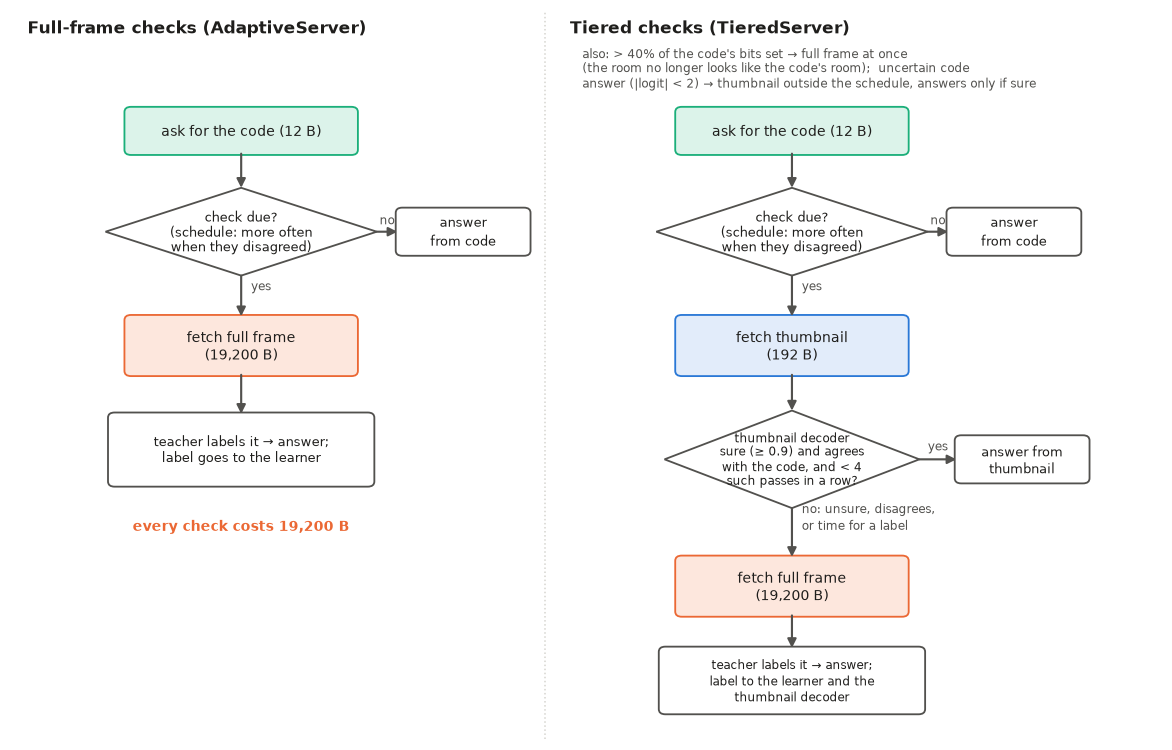

In [3]:
def flow(ax, x0, tiered):
    c = x0 + 2.6
    box(ax, c - 1.4, 9.0, 2.8, 0.7, 'ask for the code (12 B)', fc=TINT['aqua'], ec=AQUA)
    diamond(ax, c, 7.8, 3.3, 1.35, 'check due?\n(schedule: more often\nwhen they disagreed)')
    arrow(ax, c, 9.0, c, 8.475)
    box(ax, c + 1.9, 7.45, 1.6, 0.7, 'answer\nfrom code', fc='white', fs=8.5)
    arrow(ax, c + 1.65, 7.8, c + 1.9, 7.8, 'no', off=(0, 0.05), fs=8)
    if not tiered:
        box(ax, c - 1.4, 5.6, 2.8, 0.9, 'fetch full frame\n(19,200 B)', fc=TINT['orange'], ec=ORANGE)
        arrow(ax, c, 7.125, c, 6.5, 'yes', off=(0.12, 0), ha='left', fs=8)
        box(ax, c - 1.6, 3.9, 3.2, 1.1, 'teacher labels it → answer;\nlabel goes to the learner', fc='white', fs=8.5)
        arrow(ax, c, 5.6, c, 5.0)
        ax.text(c, 3.2, 'every check costs 19,200 B', ha='center', fontsize=9, color=ORANGE, fontweight='bold')
        return
    box(ax, c - 1.4, 5.6, 2.8, 0.9, 'fetch thumbnail\n(192 B)', fc=TINT['blue'], ec=BLUE)
    arrow(ax, c, 7.125, c, 6.5, 'yes', off=(0.12, 0), ha='left', fs=8)
    diamond(ax, c, 4.3, 3.1, 1.5, 'thumbnail decoder\nsure (≥ 0.9) and agrees\nwith the code, and < 4\nsuch passes in a row?', fs=8)
    arrow(ax, c, 5.6, c, 5.05)
    box(ax, c + 2.0, 3.95, 1.6, 0.7, 'answer from\nthumbnail', fc='white', fs=8.5)
    arrow(ax, c + 1.55, 4.3, c + 2.0, 4.3, 'yes', off=(0, 0.05), fs=8)
    box(ax, c - 1.4, 1.9, 2.8, 0.9, 'fetch full frame\n(19,200 B)', fc=TINT['orange'], ec=ORANGE)
    arrow(ax, c, 3.55, c, 2.8, 'no: unsure, disagrees,\nor time for a label', off=(0.12, 0), ha='left', fs=8)
    box(ax, c - 1.6, 0.4, 3.2, 1.0, 'teacher labels it → answer;\nlabel to the learner and the\nthumbnail decoder', fc='white', fs=8)
    arrow(ax, c, 1.9, c, 1.4)
    # side paths
    ax.text(c - 2.55, 9.95, 'also: > 40% of the code\'s bits set → full frame at once\n'
            '(the room no longer looks like the code\'s room);  uncertain code\n'
            'answer (|logit| < 2) → thumbnail outside the schedule, answers only if sure',
            fontsize=7.8, color=MUTED, va='bottom', linespacing=1.3)

fig, ax = canvas(14, 11.2, (13.5, 8.6))
ax.text(0.2, 10.85, 'Full-frame checks (AdaptiveServer)', fontsize=11, fontweight='bold', color=INK)
ax.text(6.8, 10.85, 'Tiered checks (TieredServer)', fontsize=11, fontweight='bold', color=INK)
flow(ax, 0.2, False); flow(ax, 6.9, True)
ax.axvline(6.5, color='#d6d5d0', lw=1, ls=':')
plt.show()


**One query, before and after.** With full-frame checks (left), every check is a full frame for the teacher. With tiered checks (right), a check first asks for a thumbnail, and the full frame is fetched only when the thumbnail decoder is unsure, disagrees with the code, or has passed four checks in a row (so the teacher keeps supplying labels). Two side paths: a code reply with more than 40% of its bits set goes straight to a full frame (the room may have changed), and an uncertain code answer gets a thumbnail outside the schedule, which answers only if it is sure and never leads to a full frame.

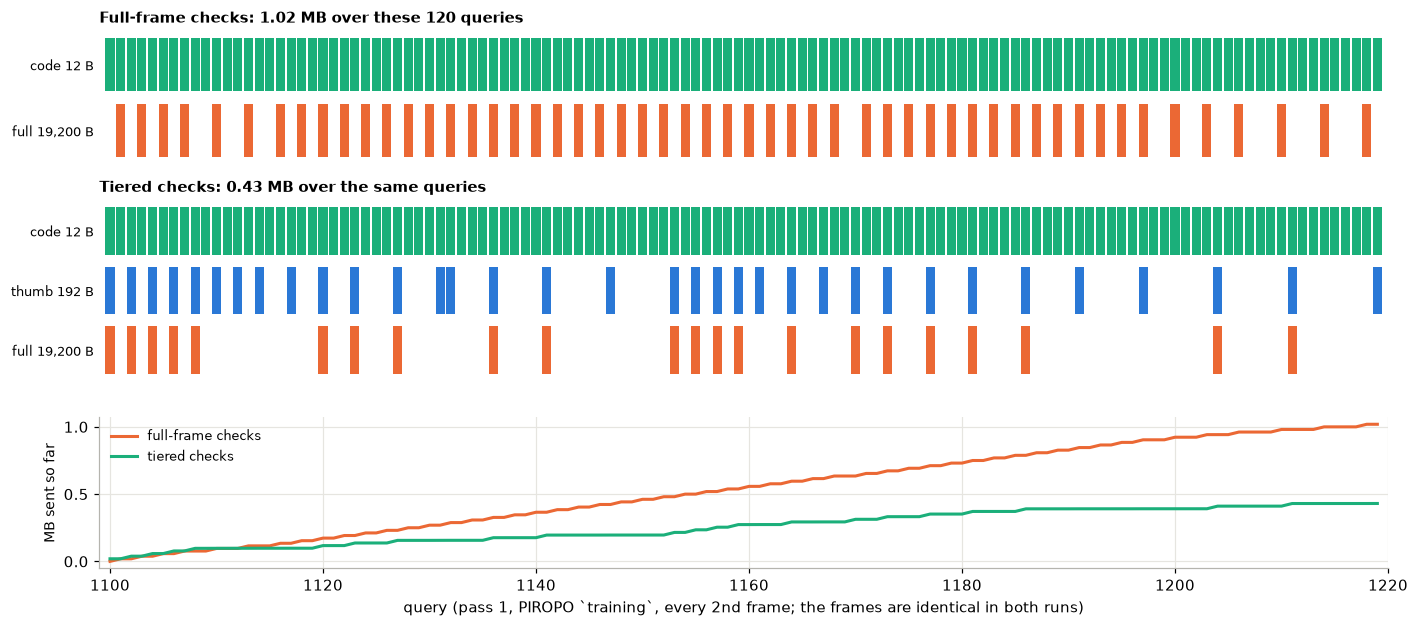

In [4]:
def load(name):
    with np.load(RES / f'{name}.npz') as z:
        n = len(z['label'])
        return pd.DataFrame({k: z[k] for k in z.files if k != 'meta' and z[k].shape == (n,)})

full = load('piropo_detector_online_pixels_full_b200')
tier = load('piropo_detector_online_pixels_tiered_b200')
assert (full.idx.values == tier.idx.values).all()
A, Bq = 1100, 1220
fig, axs = plt.subplots(3, 1, figsize=(13, 5.8), sharex=True, gridspec_kw=dict(height_ratios=[1.4, 1.9, 1.6]))
q = np.arange(A, Bq)

def lane(ax, df, rows):
    for r, (label, mask, color) in enumerate(rows):
        m = mask(df.iloc[A:Bq]).values.astype(bool)
        ax.bar(q[m], 0.8, bottom=len(rows) - 1 - r + 0.1, width=0.85, color=color, linewidth=0)
    ax.set_yticks(np.arange(len(rows)) + 0.5, [r[0] for r in rows][::-1], fontsize=8.5)
    ax.set_ylim(0, len(rows)); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.grid(False)

lane(axs[0], full, [('code 12 B', lambda d: d.used_code, AQUA), ('full 19,200 B', lambda d: d.explored, ORANGE)])
axs[0].set_title(f'Full-frame checks: {full.up_bytes[A:Bq].sum() / 1e6:.2f} MB over these {Bq - A} queries',
                 loc='left', fontsize=10)
lane(axs[1], tier, [('code 12 B', lambda d: d.used_code, AQUA), ('thumb 192 B', lambda d: d.thumbed, BLUE),
                    ('full 19,200 B', lambda d: d.explored, ORANGE)])
axs[1].set_title(f'Tiered checks: {tier.up_bytes[A:Bq].sum() / 1e6:.2f} MB over the same queries', loc='left', fontsize=10)
for df, c, lab in [(full, ORANGE, 'full-frame checks'), (tier, AQUA, 'tiered checks')]:
    axs[2].plot(q, df.up_bytes[A:Bq].cumsum() / 1e6, color=c, lw=2, label=lab)
axs[2].set_ylabel('MB sent so far', fontsize=9); axs[2].legend(frameon=False, fontsize=8.5, loc='upper left')
axs[2].spines[['top', 'right']].set_visible(False); axs[2].grid(color='#e6e5e0')
for ax in axs[:2]:
    ax.set_xlim(A - 1, Bq)
axs[2].set_xlabel(f'query (pass 1, PIROPO `{tier.seq[A]}`, every 2nd frame; the frames are identical in both runs)')
plt.tight_layout(); plt.show()


**The same 120 queries under both kinds of check** (PIROPO `training`, queries 1,100–1,219 of the first pass; the frames are the same in both runs). Each column is one query, and a coloured cell means that reply was requested. With full-frame checks the server fetches a full frame on 53 of the 120 queries (the schedule keeps the check interval at 2–5). With tiered checks 34 queries get a thumbnail and 22 a full frame, mostly early in the stretch while the thumbnail decoder is still unsure. Over this stretch that is 1.02 MB against 0.43 MB, at 78% and 80% correct answers.

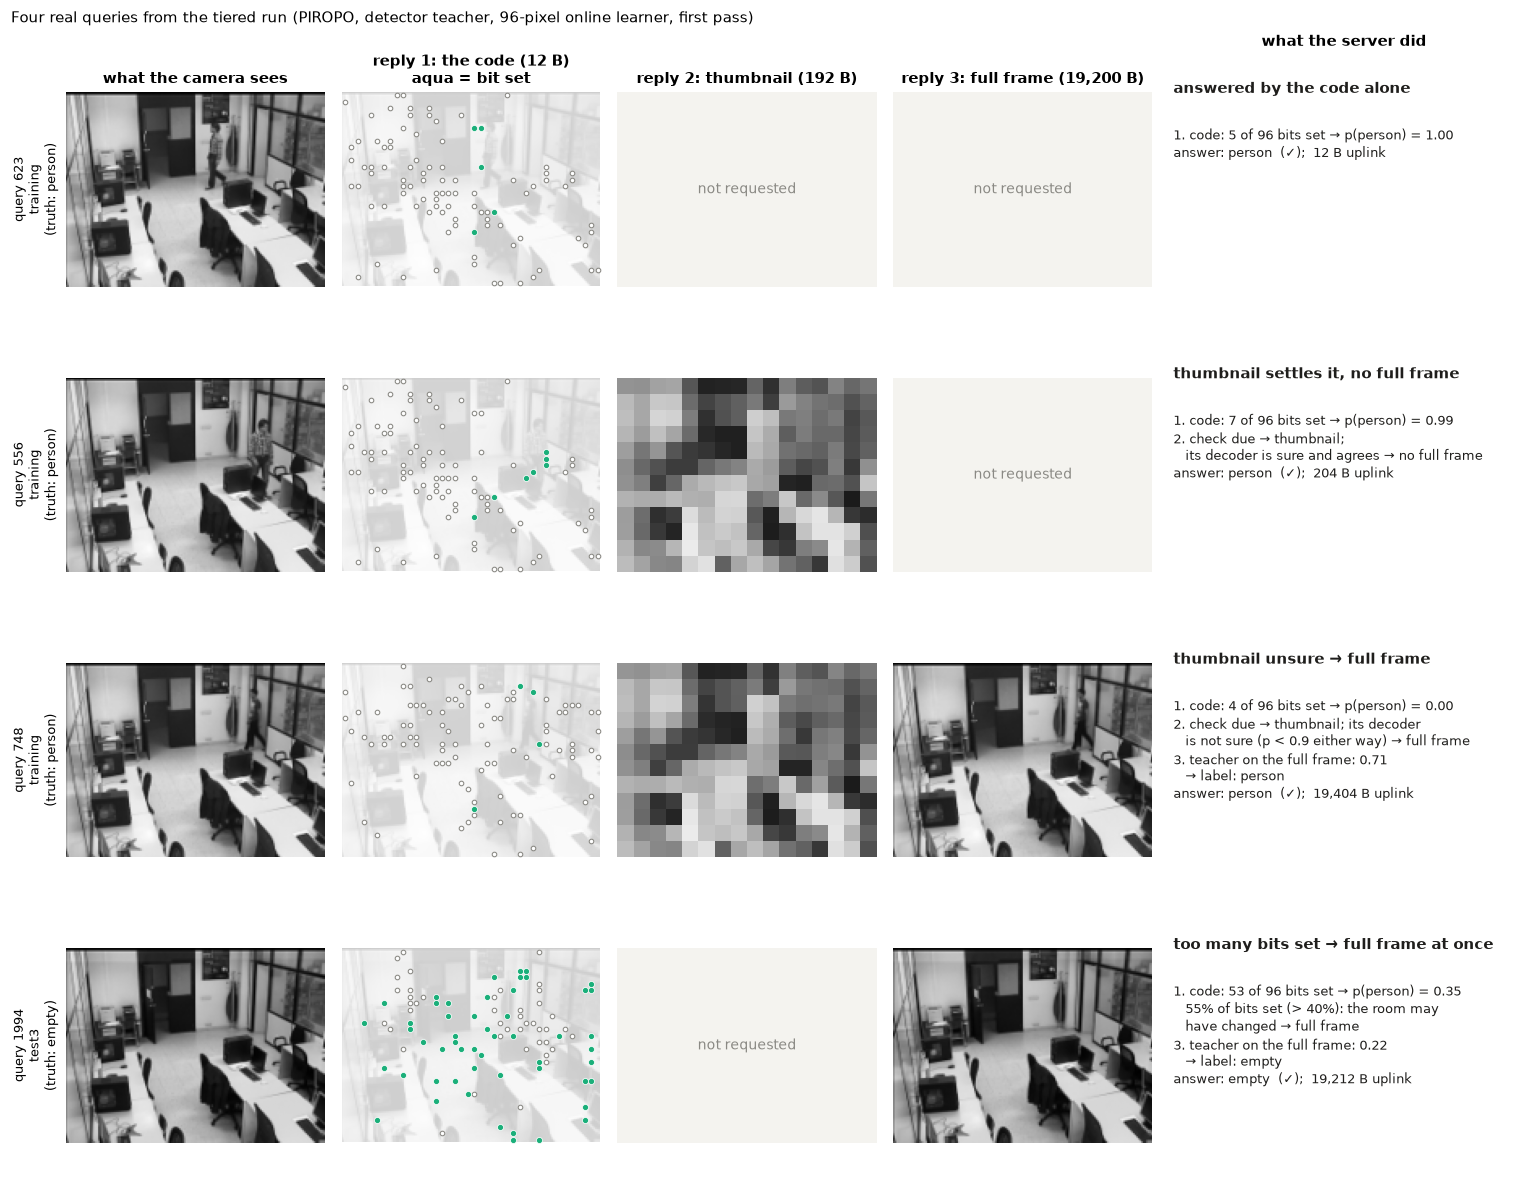

In [5]:
from semwisp.frames import load_frames, load_mall_tile
from semwisp.tag.interval import IntervalCode, cell_sums, code_bits
from semwisp.tag.thumbnail import block_mean
from semwisp.server.adaptive import CachedTeacher
P = load_frames(['training', 'test3', 'test1', 'training_seats', 'test2'])

def snapshots(name):
    z = np.load(RES / 'snapshots' / f'{name}.npz')
    return {k: z[k] for k in z.files}

def code_at(snap, q):
    """(IntervalCode, coef, intercept) on the tag at query q: the last code sent on or before it."""
    j = np.searchsorted(snap['query'], q, side='right') - 1
    return IntervalCode(np.arange(snap['rects'].shape[1]), snap['lo'][j], snap['hi'][j], snap['rects'][j]), snap['coef'][j], snap['intercept'][j]

def code_pixels(code):
    r = code.rects
    return r[:, 0] + r[:, 4] // 2, r[:, 1] + r[:, 4] // 2

def tidy(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

def blank(ax, text, frame=True):
    tidy(ax); ax.set_facecolor('#f4f3ef' if frame else 'white')
    ax.set_xlim(0, 160); ax.set_ylim(120, 0); ax.set_aspect('equal' if frame else 'auto')
    ax.text(80, 60, text, ha='center', va='center', fontsize=9, color=GRAY)

TS = snapshots('piropo_detector_online_pixels_tiered_b200')
tier['frame'] = [P[s]['X'][2 * i] for s, i in zip(tier.seq, tier.idx)]       # the run used every 2nd frame
first = tier[(tier['pass'] == 1) & (tier.index > 300)]
right = first.answer == first.label
picks = [('answered by the code alone', first[~first.thumbed & ~first.explored & (first.label == 1) & right].index[40]),
         ('thumbnail settles it, no full frame', first[first.thumbed & ~first.explored & (first.label == 1) & right].index[25]),
         ('thumbnail unsure → full frame', first[(first.why == 'unsure') & (first.label == 1) & right].index[20]),
         ('too many bits set → full frame at once', first[(first.why == 'anomaly') & (first.seq == 'test3')].index[0])]
fig, axs = plt.subplots(len(picks), 5, figsize=(14.5, 2.75 * len(picks)),
                        gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 1.35]))
for r, (title, q) in enumerate(picks):
    row = tier.loc[q]; x = row.frame
    code, coef, icpt = code_at(TS, q)
    bits = code_bits(cell_sums(x, code.table), code)
    logit = float(bits @ coef + icpt)
    if row.used_code and not row.thumbed and not row.explored:
        assert (logit > 0) == bool(row.answer)
    ax = axs[r, 0]; tidy(ax); ax.imshow(x, cmap='gray', vmin=0, vmax=255)
    ax.set_ylabel(f'query {q}\n{row.seq}\n(truth: {"person" if row.label else "empty"})', fontsize=8.5)
    ax = axs[r, 1]; tidy(ax)
    ax.imshow(x, cmap='gray', vmin=0, vmax=255, alpha=0.2)
    px, py = code_pixels(code)
    ax.scatter(px[bits == 0], py[bits == 0], s=9, facecolor='white', edgecolor=GRAY, lw=0.7)
    ax.scatter(px[bits == 1], py[bits == 1], s=16, color=AQUA, edgecolor='white', lw=0.5)
    ax.set_xlim(0, 160); ax.set_ylim(120, 0)
    ax = axs[r, 2]
    if row.thumbed:
        tidy(ax); ax.imshow(block_mean(x, 16, 12), cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    else:
        blank(ax, 'not requested')
    ax = axs[r, 3]
    if row.explored:
        tidy(ax); ax.imshow(x, cmap='gray', vmin=0, vmax=255)
    else:
        blank(ax, 'not requested')
    if r == 0:
        for ax, t in zip(axs[0], ['what the camera sees', 'reply 1: the code (12 B)\naqua = bit set',
                                  'reply 2: thumbnail (192 B)', 'reply 3: full frame (19,200 B)', 'what the server did']):
            ax.set_title(t, fontsize=9.5)
    p = 1 / (1 + np.exp(-logit))
    steps = [f'1. code: {int(bits.sum())} of 96 bits set → p(person) = {p:.2f}']
    if row.why == 'anomaly':
        steps.append(f'   {bits.mean():.0%} of bits set (> 40%): the room may\n   have changed → full frame')
    elif row.thumbed and row.explored:
        steps.append('2. check due → thumbnail; its decoder\n   is not sure (p < 0.9 either way) → full frame')
    elif row.thumbed:
        why2 = 'check due' if abs(logit) >= 2 else 'code unsure (|logit| < 2)'
        steps.append(f'2. {why2} → thumbnail;\n   its decoder is sure and agrees → no full frame')
    if row.explored:
        steps.append(f'{len(steps) + 1}. teacher on the full frame: {row.score:.2f}\n'
                     f'   → label: {"person" if row.score >= 0.6 else "empty" if row.score <= 0.3 else "none (unsure)"}')
    steps.append(f'answer: {"person" if row.answer else "empty"}  '
                 f'({"✓" if row.answer == row.label else "✗"});  {row.up_bytes:,} B uplink')
    ax = axs[r, 4]; blank(ax, '', frame=False)
    ax.text(2, 12, title, fontsize=9.5, fontweight='bold', va='top', color=INK)
    ax.text(2, 32, '\n'.join(steps), fontsize=8.5, va='top', color=INK, linespacing=1.35)
fig.suptitle('Four real queries from the tiered run (PIROPO, detector teacher, 96-pixel online learner, first pass)',
             x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.show()


**Four real queries** from the first pass of the tiered run, chosen as typical correct cases of each path (the camera image in the first column is for us; the server sees only the replies it asked for).
1. **Code alone (query 623).** 5 of the 96 bits are set, near the person; the decoder says person with p = 1.00. Cost: 12 bytes.
2. **The thumbnail settles a check (query 556).** The code says person (p = 0.99). A check was due, so the server asked for the thumbnail; the thumbnail decoder was sure and agreed, so no full frame was fetched. Cost: 204 bytes.
3. **The thumbnail is unsure, so a full frame is fetched (query 748).** The code missed the person (4 bits, p = 0.00). The thumbnail decoder could not decide, so the server fetched the full frame; the teacher scored it 0.71, the answer is "person", and the frame becomes a person label for the learner. Labels like this one, on a frame the code got wrong, are the ones that improve the next code. Cost: 19,404 bytes.
4. **Too many bits set (query 1,994).** The first frames of `test3` are darker than `training`, so 53 of 96 pixels are outside their usual range. Rather than read that as a person, the server treats it as a possible change of room and fetches a full frame at once; the teacher says empty (0.22), which is right.

## 1. PIROPO: full-frame checks against tiered checks

In [6]:
rows = []
for name, (m, df) in runs.items():
    if m['stream'] != 'piropo':
        continue
    for p, g in df.groupby('pass'):
        s = summary(g)
        rows.append(dict(teacher=m['teacher'], learner=m['learner'], check=m['check'], **{'pass': p},
                         balanced_acc=s['balanced_accuracy'], bytes_per_query=s['up_bytes_per_query'],
                         full_frame_rate=s['full_frame_rate'], thumb_rate=s.get('thumb_rate', 0.0), reconfigs=s['reconfigs']))
piropo = pd.DataFrame(rows).sort_values(['teacher', 'learner', 'pass', 'check'])
display(piropo.set_index(['teacher', 'learner', 'pass', 'check']))

balanced_acc  bytes_per_query  \
teacher  learner       pass check                                   
detector batch_cells   1    full           0.841         5688.458   
                            tiered         0.826         3587.778   
                       2    full           0.884          513.261   
                            tiered         0.879         2013.779   
         online_cells  1    full           0.843         6713.509   
                            tiered         0.812         4676.473   
                       2    full           0.852         6190.469   
                            tiered         0.857         2253.202   
         online_pixels 1    full           0.805         8572.119   
                            tiered         0.814         5113.584   
                       2    full           0.844         5638.518   
                            tiered         0.855         2997.040   
oracle   batch_cells   1    full           0.904         5570.228   
                            tiered         0.922         3343.445   
                       2    full           0.954          879.351   
                            tiered         0.921          590.647   
         online_cells  1    full           0.899         5406.896   
                            tiered         0.898         3369.578   
                       2    full           0.917         2478.882   
                            tiered         0.942         2398.060   
         online_pixels 1    full           0.886         6657.233   
                            tiered         0.851         3876.134   
                       2    full           0.935         1521.416   
                            tiered         0.932         1256.480   

                                    full_frame_rate  thumb_rate  reconfigs  
teacher  learner       pass check                                           
detector batch_cells   1    full              0.296       0.000         15  
                            tiered            0.180       0.587          8  
                       2    full              0.026       0.000          2  
                            tiered            0.100       0.452          5  
         online_cells  1    full              0.349       0.000         18  
                            tiered            0.239       0.361         11  
                       2    full              0.322       0.000         20  
                            tiered            0.113       0.350          7  
         online_pixels 1    full              0.446       0.000         24  
                            tiered            0.262       0.379         13  
                       2    full              0.293       0.000         18  
                            tiered            0.152       0.381          9  
oracle   batch_cells   1    full              0.290       0.000         16  
                            tiered            0.168       0.546          8  
                       2    full              0.045       0.000          3  
                            tiered            0.026       0.432          2  
         online_cells  1    full              0.281       0.000         16  
                            tiered            0.172       0.272          8  
                       2    full              0.128       0.000          8  
                            tiered            0.121       0.371          8  
         online_pixels 1    full              0.346       0.000         20  
                            tiered            0.198       0.358         10  
                       2    full              0.079       0.000          5  
                            tiered            0.063       0.204          4

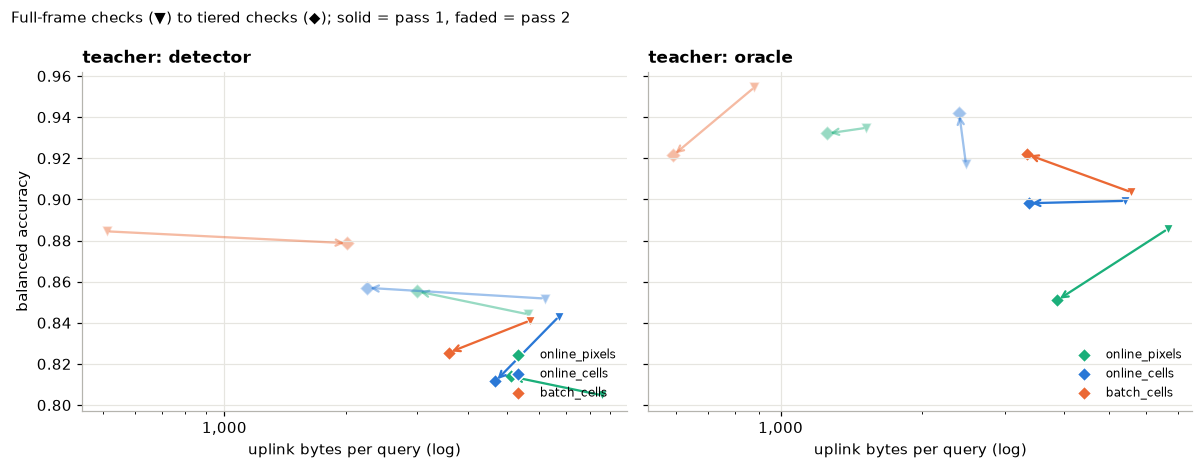

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, teacher in zip(axs, ['detector', 'oracle']):
    for learner, color in LC.items():
        d = piropo[(piropo.teacher == teacher) & (piropo.learner == learner)]
        for p, alpha in [(1, 1.0), (2, 0.45)]:
            a = d[(d['pass'] == p) & (d.check == 'full')]; b = d[(d['pass'] == p) & (d.check == 'tiered')]
            if len(a) and len(b):
                ax.annotate('', (b.bytes_per_query.iloc[0], b.balanced_acc.iloc[0]), (a.bytes_per_query.iloc[0], a.balanced_acc.iloc[0]),
                            arrowprops=dict(arrowstyle='->', color=color, alpha=alpha, lw=1.5))
                ax.scatter(a.bytes_per_query, a.balanced_acc, marker='v', s=45, color=color, alpha=alpha, edgecolor='white')
                ax.scatter(b.bytes_per_query, b.balanced_acc, marker='D', s=45, color=color, alpha=alpha, edgecolor='white',
                           label=learner if p == 1 else None)
    logx(ax); ax.set_title(f'teacher: {teacher}', loc='left'); ax.set_xlabel('uplink bytes per query (log)')
    ax.legend(frameon=False, fontsize=8, loc='lower right')
axs[0].set_ylabel('balanced accuracy')
fig.suptitle('Full-frame checks (▼) to tiered checks (◆); solid = pass 1, faded = pass 2', x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.show()

**Reading the table and chart.** Each arrow goes from full-frame checks (▼) to tiered checks (◆) for one learner; solid is the first pass, faded the second.
* **First pass, the honest test.** Every arrow points left: 1.4–1.7× fewer bytes. Accuracy moves by −0.035 to +0.02: with detector labels slightly down for the block-based learners and up for the 96-pixel one; with true labels up for the batch learner (+0.02) and down for the 96-pixel one (−0.035).
* **Second pass.** Mixed. Where the full-frame loop had already settled (batch learner, 2.6–4.5% full frames), tiered checks do not help, and with detector labels they cost bytes (513 → 2,014 B), because the thumbnail decoder's uncertainty keeps sending checks on to the full frame. Where it had not settled (the online learners), tiered checks roughly halve the bytes or better with detector labels (6.2 → 2.3 KB and 5.6 → 3.0 KB).
* The saving is real, but the full-frame rate is still 17–26% in the first pass, so the uplink is still kilobytes per query. Section 2 shows why.

## 2. Why full frames are still fetched

,queries,bootstrap,anomaly,unsure,disagree,floor
run,,,,,,
detector / batch_cells,3409,213,32,250,79,41
detector / online_cells,3409,213,10,420,129,44
detector / online_pixels,3409,213,6,475,155,44
oracle / batch_cells,3409,200,33,131,132,77
oracle / online_cells,3409,200,9,143,152,83
oracle / online_pixels,3409,200,7,148,228,91


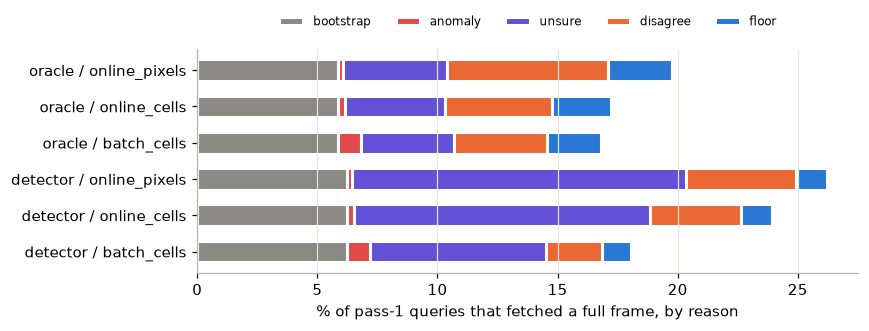

In [8]:
REASONS = ['bootstrap', 'anomaly', 'unsure', 'disagree', 'floor']
rows = []
for name, (m, df) in runs.items():
    if m['check'] != 'tiered' or m['bootstrap'] != 200 or m['stream'] != 'piropo':
        continue
    d = df[df['pass'] == 1]
    vc = d[d.explored.astype(bool)].why.value_counts()
    rows.append(dict(run=f"{m['teacher']} / {m['learner']}", queries=len(d), **{r: int(vc.get(r, 0)) for r in REASONS}))
why = pd.DataFrame(rows).set_index('run'); display(why)
shares = why[REASONS].div(why.queries, axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(shares)); colors = [GRAY, '#e34948', '#6250d6', ORANGE, BLUE]
for r, c in zip(REASONS, colors):
    ax.barh(shares.index, shares[r], left=left, color=c, label=r, edgecolor='white', linewidth=2, height=0.6)
    left += shares[r].values
ax.set_xlabel('% of pass-1 queries that fetched a full frame, by reason'); ax.legend(frameon=False, ncol=5, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, 1.2))
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

**Why full frames are still fetched.** *bootstrap*: the first 200 labelled frames (a setting). *unsure*: a scheduled thumbnail check the thumbnail decoder could not decide. *disagree*: it was confident but disagreed with the code. *floor*: four trusted thumbnail checks in a row. *anomaly*: the code reply had more than 40% of its bits set.
* With detector labels, *unsure* is the largest share by far, 7–14% of all queries. The thumbnail decoder is trained on the detector's labels, which are wrong about one time in seven on PIROPO, so its probabilities rarely reach 0.9. With true labels *unsure* drops to about 4%, and *disagree* (the code being wrong) is as large.
* *anomaly* is small (0.2–1% of queries) but it is what lets a change be noticed between scheduled checks.
* So the lever is now the **teacher**: a thumbnail decoder that can be trusted needs labels that can be trusted.

## 3. Moving the tag, with no labels anywhere

In [9]:
def rooms(df):
    df = df.copy(); df['room'] = df.seq.str.replace(' (test2)', '', regex=False)
    return [(r, g.reset_index(drop=True)) for r, g in df.groupby('room', sort=False)]

rows = []
for name, (m, df) in runs.items():
    if m['stream'] != 'switch' or m['bootstrap'] != 200:
        continue
    for room, g in rooms(df):
        r = readaptation(g)
        after = r['after'] or {}
        rows.append(dict(teacher=m['teacher'], learner=m['learner'], check=m['check'], room=room, queries=len(g),
                         detect=r['detect_queries'], deploy=r['deploy_queries'], full_frames_to_deploy=r['full_frames_to_deploy'],
                         acc_after=after.get('balanced_accuracy'), full_rate_after=after.get('full_frame_rate'),
                         bytes_after=after.get('up_bytes_per_query'), acc_whole=r['whole']['balanced_accuracy'],
                         bytes_whole=r['whole']['up_bytes_per_query']))
switch = pd.DataFrame(rows)
display(switch.set_index(['teacher', 'learner', 'check', 'room']))

queries  detect  deploy  \
teacher  learner       check  room                                          
detector batch_cells   full   room A (training)      1987     0.0     213   
                              room B (mall tile)     2000     NaN      32   
                              room A, rearranged     1110     NaN     193   
                       tiered room A (training)      1987     0.0     213   
                              room B (mall tile)     2000     NaN     117   
                              room A, rearranged     1110     NaN      27   
         online_cells  full   room A (training)      1987     0.0     213   
                              room B (mall tile)     2000    32.0     238   
                              room A, rearranged     1110    15.0     231   
                       tiered room A (training)      1987     0.0     213   
                              room B (mall tile)     2000    32.0     238   
                              room A, rearranged     1110    14.0     230   
         online_pixels full   room A (training)      1987     0.0     213   
                              room B (mall tile)     2000    48.0     255   
                              room A, rearranged     1110    15.0     231   
                       tiered room A (training)      1987     0.0     213   
                              room B (mall tile)     2000    32.0     238   
                              room A, rearranged     1110    14.0     230   
oracle   batch_cells   full   room A (training)      1987     0.0     200   
                              room B (mall tile)     2000     NaN     114   
                              room A, rearranged     1110     NaN     167   
                       tiered room A (training)      1987     0.0     200   
                              room B (mall tile)     2000     NaN      81   
                              room A, rearranged     1110     NaN      69   
         online_cells  full   room A (training)      1987     0.0     200   
                              room B (mall tile)     2000    31.0     290   
                              room A, rearranged     1110   157.0     357   
                       tiered room A (training)      1987     0.0     200   
                              room B (mall tile)     2000    46.0     314   
                              room A, rearranged     1110   164.0     364   
         online_pixels full   room A (training)      1987     0.0     200   
                              room B (mall tile)     2000    31.0     290   
                              room A, rearranged     1110   159.0     359   
                       tiered room A (training)      1987     0.0     200   
                              room B (mall tile)     2000    46.0     314   
                              room A, rearranged     1110   164.0     364   

                                                  full_frames_to_deploy  \
teacher  learner       check  room                                        
detector batch_cells   full   room A (training)                     213   
                              room B (mall tile)                     16   
                              room A, rearranged                     47   
                       tiered room A (training)                     213   
                              room B (mall tile)                     51   
                              room A, rearranged                     13   
         online_cells  full   room A (training)                     213   
                              room B (mall tile)                    221   
                              room A, rearranged                    223   
                       tiered room A (training)                     213   
                              room B (mall tile)                    221   
                              room A, rearranged                    221   
         online_pixels full   room A (training)                     213  

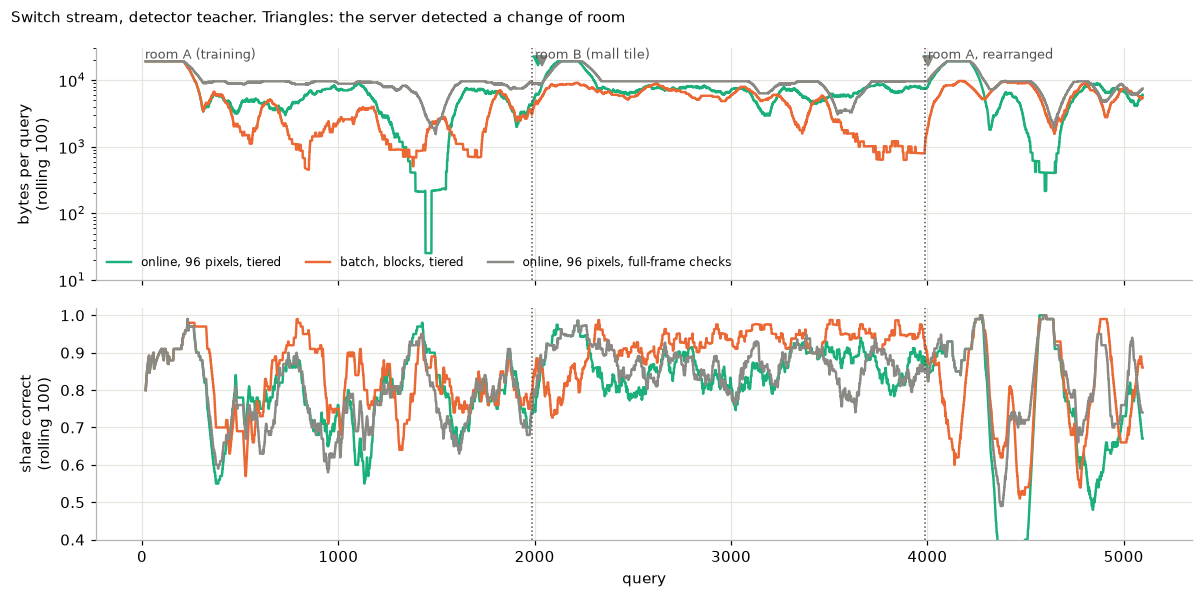

In [10]:
def rolling(df, col, w=100):
    return df[col].astype(float).rolling(w, min_periods=20).mean()

fig, axs = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for name, color, label in [('switch_detector_online_pixels_tiered_b200', AQUA, 'online, 96 pixels, tiered'),
                           ('switch_detector_batch_cells_tiered_b200', ORANGE, 'batch, blocks, tiered'),
                           ('switch_detector_online_pixels_full_b200', GRAY, 'online, 96 pixels, full-frame checks')]:
    if name not in runs:
        continue
    df = runs[name][1]
    axs[0].plot(rolling(df, 'up_bytes'), color=color, lw=1.6, label=label)
    ok = df.label >= 0
    axs[1].plot((df.answer == df.label).where(ok).rolling(100, min_periods=20).mean(), color=color, lw=1.6)
    if 'changed' in df:
        for i in np.flatnonzero(df.changed.values.astype(bool)):
            axs[0].plot(i, 19500, 'v', color=color, ms=6)
df = runs['switch_detector_online_pixels_tiered_b200'][1]
starts = df.groupby(df.seq.str.replace(' (test2)', '', regex=False), sort=False).head(1).index
for ax in axs:
    for s in starts[1:]:
        ax.axvline(s, color='#52514e', lw=1, ls=':')
for s, (room, _) in zip(starts, rooms(df)):
    axs[0].text(s + 15, 21000, room, fontsize=8.5, color='#52514e')
axs[0].set_yscale('log'); axs[0].set_ylabel('bytes per query\n(rolling 100)'); axs[0].set_ylim(10, 30000)
axs[1].set_ylabel('share correct\n(rolling 100)'); axs[1].set_xlabel('query'); axs[1].set_ylim(0.4, 1.02)
axs[0].legend(frameon=False, fontsize=8, loc='lower left', ncol=3)
fig.suptitle('Switch stream, detector teacher. Triangles: the server detected a change of room', x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.show()

**Reading the table and chart.** *detect*: queries from the move until the server noticed and went back to full frames (blank for the batch learner, which has no change detector). *deploy*: queries until a code learned after the move was on the tag; for the batch learner that is just its first routine refit after the move, which can come before its window holds mostly new frames.
* **With no labels anywhere, the online learner detects both moves**: 32–48 queries into the Mall tile and 14–15 into the rearranged room. (With true labels it takes 157–164 queries there, because that stretch starts with people present and the true labels say so; the detector's mistaken "empty" labels happen to trigger the reset sooner.) A new code is on the tag 230–255 queries after the move, and about 220 full frames (4.2 MB) are fetched to get there.
* **After the move to the Mall tile** every learner recovers to 0.88–0.93. **After the return to the rearranged room** the detector-taught online learners reach only 0.66–0.80, against 0.80 for the batch learner; the timeline shows long dips there (to 0.4–0.5 around queries 4,300 and 4,800) that none of the loops catch.
* **The change detector is paid for in bytes**: the online learner goes to full frames for ~220 queries after each move (the plateaus at 19,200 bytes in the timeline). The batch learner never does, and pays in accuracy right after each move instead.

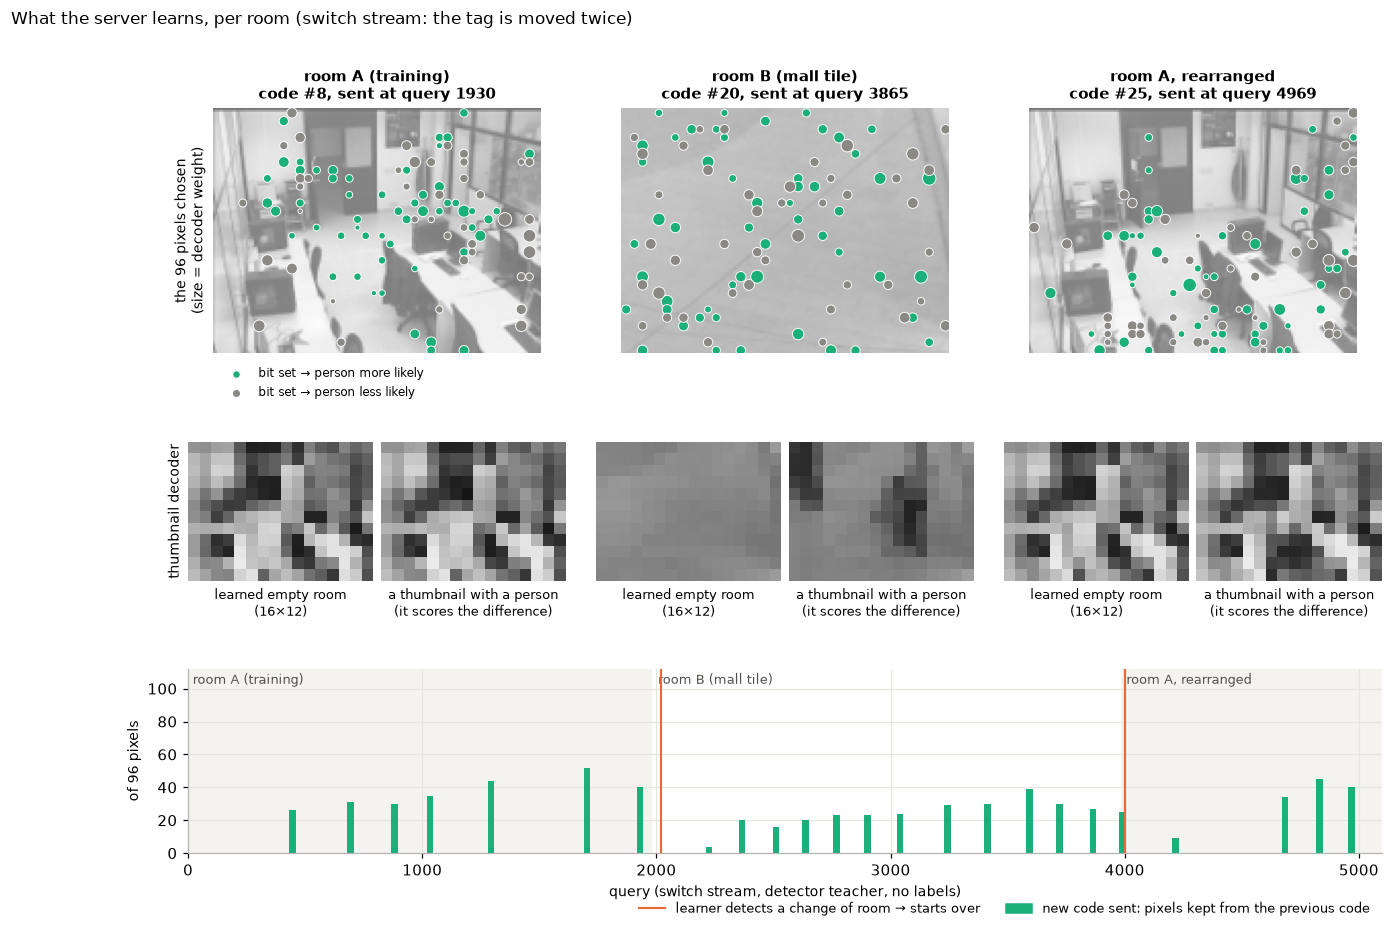

In [11]:
SW = snapshots('switch_detector_online_pixels_tiered_b200')
sw = load('switch_detector_online_pixels_tiered_b200')
mall = load_mall_tile()
ROOM_FRAMES = [('room A (training)', P['training']), ('room B (mall tile)', mall), ('room A, rearranged', P['training_seats'])]
room_of = lambda seq: seq.replace(' (test2)', '')
fig = plt.figure(figsize=(14, 8.8))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 0.62, 0.75], hspace=0.42, wspace=0.08)
for c, (room, F) in enumerate(ROOM_FRAMES):
    j = np.flatnonzero(np.array([room_of(s_) for s_ in SW['seq']]) == room)[-1]        # last code sent in this room
    code = IntervalCode(np.arange(96), SW['lo'][j], SW['hi'][j], SW['rects'][j]); coef = SW['coef'][j]
    X, y = F['X'], F['label']
    flat = (X.std(2) < 2).mean(1) > 0.05
    ok = ~F['bad'].astype(bool) & ~flat
    empty = X[np.flatnonzero(ok & (y == 0))[len(np.flatnonzero(ok & (y == 0))) // 2]]
    person = X[np.flatnonzero(ok & (y == 1))[len(np.flatnonzero(ok & (y == 1))) // 2]]
    px, py = code_pixels(code)
    w = coef / np.abs(coef).max()
    ax = fig.add_subplot(gs[0, c]); tidy(ax)
    ax.imshow(empty, cmap='gray', vmin=0, vmax=255, alpha=0.55)
    pos = w > 0
    ax.scatter(px[pos], py[pos], s=8 + 70 * w[pos], color=AQUA, edgecolor='white', lw=0.6, label='bit set → person more likely')
    ax.scatter(px[~pos], py[~pos], s=8 + 70 * -w[~pos], color=GRAY, edgecolor='white', lw=0.6, label='bit set → person less likely')
    ax.set_title(f'{room}\ncode #{j + 1}, sent at query {SW["query"][j]}', fontsize=9.5)
    if c == 0:
        ax.set_ylabel('the 96 pixels chosen\n(size = decoder weight)', fontsize=9)
        ax.legend(loc='upper left', bbox_to_anchor=(0, -0.01), fontsize=8, frameon=False, ncol=1, markerscale=0.8)
    # the thumbnail decoder's picture of the empty room, next to a real frame with a person
    sub = gs[1, c].subgridspec(1, 2, wspace=0.04)
    ax = fig.add_subplot(sub[0]); tidy(ax)
    bg = SW['thumb_bg'][j]
    if np.isfinite(bg).all():
        ax.imshow(bg.reshape(12, 16), cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_xlabel('learned empty room\n(16×12)', fontsize=8.5)
    if c == 0:
        ax.set_ylabel('thumbnail decoder', fontsize=9)
    ax = fig.add_subplot(sub[1]); tidy(ax)
    ax.imshow(block_mean(person, 16, 12), cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_xlabel('a thumbnail with a person\n(it scores the difference)', fontsize=8.5)
# timeline of the codes
ax = fig.add_subplot(gs[2, :])
kept = [np.nan] + [len({tuple(r) for r in SW['rects'][k]} & {tuple(r) for r in SW['rects'][k - 1]}) for k in range(1, len(SW['query']))]
seq_room = sw.seq.map(room_of)
starts = seq_room.ne(seq_room.shift()).to_numpy().nonzero()[0]
for k, s0 in enumerate(starts):
    s1 = starts[k + 1] if k + 1 < len(starts) else len(sw)
    ax.axvspan(s0, s1, color=['#f4f3ef', '#ffffff'][k % 2], zorder=0)
    ax.text(s0 + 20, 101, seq_room[s0], fontsize=8.5, color=MUTED, va='bottom')
ax.bar(SW['query'], kept, width=28, color=AQUA, zorder=2)
for qq in np.flatnonzero(sw.changed.values.astype(bool)):
    ax.axvline(qq, color=ORANGE, lw=1.4, zorder=3)
ax.plot([], [], color=ORANGE, lw=1.4, label='learner detects a change of room → starts over')
from matplotlib.patches import Patch
handles = ax.get_legend_handles_labels()[0] + [Patch(color=AQUA, label='new code sent: pixels kept from the previous code')]
ax.set_ylim(0, 112); ax.set_xlim(0, len(sw)); ax.set_ylabel('of 96 pixels', fontsize=9)
ax.set_xlabel('query (switch stream, detector teacher, no labels)', fontsize=9)
ax.legend(handles=handles, frameon=False, fontsize=8.5, loc='upper right', bbox_to_anchor=(1, -0.2), ncol=2)
ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('What the server learns, per room (switch stream: the tag is moved twice)', x=0.01, ha='left', fontsize=11)
plt.show()


**What is learned, per room** (the switch stream, detector teacher, 96-pixel online learner with tiered checks; every code it sent was recorded by `experiments/code_snapshots.py`, which replays the run and checks that it reproduces the stored one query for query).
* **Top: the code.** The last code the server sent in each room: 96 pixels, sized by the weight the server's decoder gives to each bit. Aqua: a set bit (pixel outside its usual range) is evidence for a person; gray: evidence against, typically pixels that flip with lighting and so help the decoder discount a global change. The pixels are entirely different in each room. In room A they are mostly in the back half of the room (doorway, aisle, window side), where people in `training` walk, with few on the foreground desks; in the Mall tile they are spread over the floor.
* **Middle: the thumbnail decoder.** Its picture of the empty room, a running average of the 16×12 thumbnails of frames the teacher labelled empty, next to a thumbnail with a person. It scores the difference between the two. It is rebuilt from scratch after every move.
* **Bottom: every code sent**, and how many of its 96 pixels the previous code also used. Within a room consecutive codes share only 16–52 pixels: the learner keeps swapping pixels that carry similar information. The tag is moved at queries 1,987 and 3,987. The change detector fires 32 and 14 queries later (orange lines) and the learner starts over; the first code learned in the new room is sent 238 and 230 queries after the move and shares 4 and 9 pixels with the old one. (The code sent at query 3,990 is still the Mall code: it was learned just before the move.)

## 4. Readaptation time against bootstrap length

In [12]:
rows = []
for name, (m, df) in runs.items():
    if m['stream'] != 'switch' or m['check'] != 'tiered' or m['learner'] not in ('online_pixels', 'batch_cells'):
        continue
    for room, g in rooms(df):
        r = readaptation(g); after = r['after'] or {}
        rows.append(dict(teacher=m['teacher'], learner=m['learner'], bootstrap=m['bootstrap'], room=room,
                         detect=r['detect_queries'], deploy=r['deploy_queries'], full_frames_to_deploy=r['full_frames_to_deploy'],
                         acc_after=after.get('balanced_accuracy'), acc_whole=r['whole']['balanced_accuracy'],
                         bytes_whole=r['whole']['up_bytes_per_query']))
boot = pd.DataFrame(rows).sort_values(['teacher', 'learner', 'room', 'bootstrap'])
display(boot.set_index(['teacher', 'learner', 'room', 'bootstrap']))

detect  deploy  \
teacher  learner       room               bootstrap                   
detector batch_cells   room A (training)  25            0.0      65   
                                          50            0.0      65   
                                          100           0.0     109   
                                          200           0.0     213   
                                          400           0.0     422   
                       room A, rearranged 25            NaN      97   
                                          50            NaN      97   
                                          100           NaN      73   
                                          200           NaN      27   
                                          400           NaN      69   
                       room B (mall tile) 25            NaN      15   
                                          50            NaN      15   
                                          100           NaN      89   
                                          200           NaN     117   
                                          400           NaN      17   
         online_pixels room A (training)  25            0.0      65   
                                          50            0.0      65   
                                          100           0.0     109   
                                          200           0.0     213   
                                          400           0.0     422   
                       room A, rearranged 25           14.0     146   
                                          50           16.0     153   
                                          100          14.0     146   
                                          200          14.0     230   
                                          400          16.0     461   
                       room B (mall tile) 25           32.0      58   
                                          50           32.0      84   
                                          100          32.0     134   
                                          200          32.0     238   
                                          400          32.0     446   
oracle   batch_cells   room A (training)  25            0.0      70   
                                          50            0.0      70   
                                          100           0.0     100   
                                          200           0.0     200   
                                          400           0.0     400   
                       room A, rearranged 25            NaN     137   
                                          50            NaN     137   
                                          100           NaN       5   
                                          200           NaN      69   
                                          400           NaN      99   
                       room B (mall tile) 25            NaN     129   
                                          50            NaN     129   
                                          100           NaN      79   
                                          200           NaN      81   
                                          400           NaN      61   
         online_pixels room A (training)  25            0.0      70   
                                          50            0.0      70   
                                          100           0.0     100   
                                          200           0.0     200   
                                          400           0.0     400   
                       room A, rearranged 25          162.0     304   
                                          50          164.0     304   
                                          100         164.0     304   
                                          200         164.0     364   
                                          400         164.0     564   
      

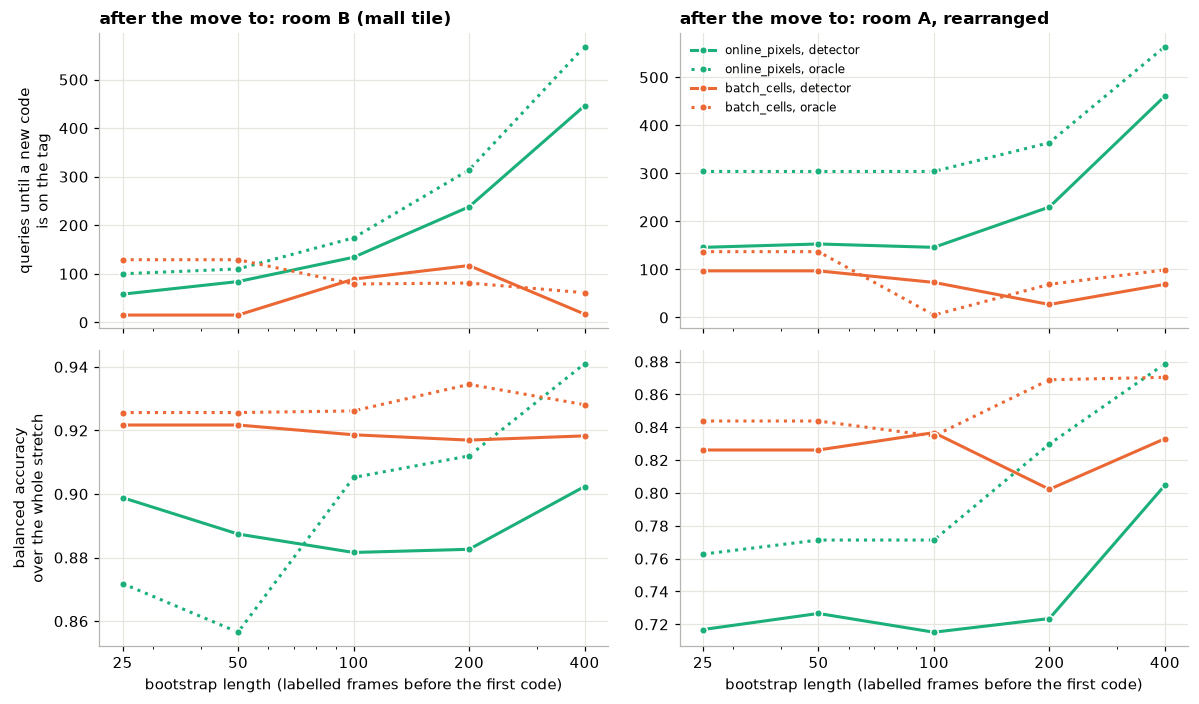

In [13]:
ROOMS = ['room B (mall tile)', 'room A, rearranged']
fig, axs = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for j, room in enumerate(ROOMS):
    for learner, color in [('online_pixels', AQUA), ('batch_cells', ORANGE)]:
        for teacher, ls in [('detector', '-'), ('oracle', ':')]:
            d = boot[(boot.room == room) & (boot.learner == learner) & (boot.teacher == teacher)].sort_values('bootstrap')
            if not len(d):
                continue
            kw = dict(color=color, ls=ls, marker='o', ms=5, markeredgecolor='white', label=f'{learner}, {teacher}')
            axs[0, j].plot(d.bootstrap, d.deploy, **kw)
            axs[1, j].plot(d.bootstrap, d.acc_whole, **kw)
    axs[0, j].set_title(f'after the move to: {room}', loc='left')
    axs[1, j].set_xlabel('bootstrap length (labelled frames before the first code)'); logx(axs[1, j])
    axs[1, j].set_xticks([25, 50, 100, 200, 400], ['25', '50', '100', '200', '400'])
axs[0, 0].set_ylabel('queries until a new code\nis on the tag'); axs[1, 0].set_ylabel('balanced accuracy\nover the whole stretch')
axs[0, 1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Bootstrap length.** The online 96-pixel learner puts a new code on the tag roughly *detect + bootstrap* queries after a move: 58, 84, 134, 238 and 446 queries into the Mall tile for bootstraps of 25 to 400 (detector teacher). A short bootstrap means a worse first code, which the online learner keeps for a while because its statistics fade slowly. Over the Mall stretch that costs little with detector labels (0.899 at 25 against 0.902 at 400) but 0.07 with true labels (0.872 against 0.941); in the rearranged room it costs 0.09 with detector labels (0.717 against 0.804) and 0.12 with true labels (0.763 against 0.879).

The batch learner is nearly flat in bootstrap length (within 0.04 everywhere), because it refits every 50 labelled frames on its window whatever the first code was. Bootstraps 25 and 50 give identical batch runs: the server also waits for 10 frames of each class before making the first code, and that condition is what binds.

**So "how long does readaptation take" has a clear answer for this loop:** detection takes 15–50 queries with detector labels, and the rest is a setting. With a 25-frame bootstrap the online learner has a new code on the tag 58–153 queries after a move (detector labels), paid for in accuracy. The batch learner has no defined readaptation point (no detector), but its accuracy is insensitive to the bootstrap, which suggests the combination in "next" below.

## Limits of this experiment
* Single runs, settings chosen once (confidence 0.9, margin 2, floor 4, anomaly 40%). PIROPO is 30 staged minutes; the second room is one Mall tile.
* The teacher on PIROPO is the COCO detector at 160×120 (0.86 balanced accuracy); on the Mall tile the same detector is far better (AUC 0.995). Every PIROPO number here is capped by it.
* Bytes, not energy: a 192-byte thumbnail check is 18 EPCs plus a block mean on the tag; what that costs relative to one EPC is unknown until `semwisp/cost.py` is measured.

## What this suggests next
* **A better teacher is now the largest lever** for both bytes and accuracy: temporal smoothing of the detector's scores, or a larger detector on the full frame, would make the thumbnail decoder confident more often and remove most *unsure* full frames.
* **Let a confident thumbnail supervise the code**, so labels for the code do not all need a full frame (trusted thumbnails were 0.95 correct with true labels).
* **Add the change detector to the batch learner**, which settles better once a room is stable; the two mechanisms are complementary.